In [9]:
import jax.numpy as jnp
import jax
import numpy as np
import matplotlib.pyplot as plt
from ase import Atoms

class GaussianND:
    def __init__(self, old_means, std_dev=0.1, bias_height=1.0):
        self.old_means = old_means  # Means: (M, N), where M is number of gaussians, N is dimensionality
        self.std_dev = std_dev  # Scalar standard deviation
        self.bias_height = bias_height  # Height scaling factor for the bias
    
    def cvs(self, positions, dims):
        # Returns the selected collective variables (x for 1D, [x, y] for 2D, etc.)
        return positions[:, :dims].flatten()
    
    def gaussian_ND(self, positions, dims):
        """
        General ND Gaussian computation.
        Args:
            positions: ASE atoms positions
            dims: Number of dimensions (1 for x, 2 for x/y)
        """
        cvs = self.cvs(positions, dims)  # Shape: (N,)
        mean_cvs = self.old_means         # Shape: (M, N)
        std_dev = self.std_dev            # Scalar standard deviation

        # Compute Gaussian for each dimension using broadcasting
        gaussian_vals = jnp.exp(-0.5 * jnp.sum(((cvs - mean_cvs) ** 2) / (0.5 * std_dev ** 2), axis=-1))

        # Sum over all means
        return self.bias_height * jnp.sum(gaussian_vals)

    # Gradient of the gaussian function wrt positions
    def grad_gaussian_ND(self, positions, dims):
        return jax.grad(self.gaussian_ND)(positions, dims)


In [26]:
# Create sample ASE atoms object for 1D (x) and 2D (x, y)
positions = np.array([[0.0, 0.0, 0.0]])  # One atom at origin (for 1D or 2D Gaussian)
atoms = Atoms(positions=positions)

# Means for Gaussian: assume two means for 2D Gaussian (1.0, 1.0) and (-1.0, -1.0)
old_means_1D = np.array([[0.0],[0.5]])  # For 1D
old_means_2D = np.array([[0.1, 0.0], [-1.0, -0.0]])  # For 2D

# Initialize GaussianND class for 1D and 2D cases
gaussian_1D = GaussianND(old_means_1D, std_dev=0.1, bias_height=1.0)
gaussian_2D = GaussianND(old_means_2D, std_dev=0.1, bias_height=1.0)

# Compute 1D and 2D Gaussian
dims_1D = 1
dims_2D = 2

gaussian_1D_val = gaussian_1D.gaussian_ND(atoms.positions, dims_1D)
gaussian_2D_val = gaussian_2D.gaussian_ND(atoms.positions, dims_2D)

print(f"1D Gaussian Value: {gaussian_1D_val}")
print(f"2D Gaussian Value: {gaussian_2D_val}")


1D Gaussian Value: 1.0
2D Gaussian Value: 0.3678794503211975


In [27]:
# Functions you provided
def original_gaussian_1D(positions, old_means, std_dev=0.1, bias_height=1.0):
    x = positions[:, 0]  # Assume 1D takes x-coordinate
    gaussian_vals = np.exp(-0.5 * ((x - old_means[:, np.newaxis]) ** 2 / (0.5 * std_dev ** 2)))
    return bias_height * np.sum(gaussian_vals, axis=0)[0]

def original_gaussian_2D(positions, old_means, std_dev=0.1, bias_height=1.0):
    x = positions[:, 0]  # x-coordinate
    y = positions[:, 1]  # y-coordinate
    gaussian_vals = np.exp(-0.5 * ((x - old_means[:, 0]) ** 2 / (0.5 * std_dev ** 2)) -
                           0.5 * ((y - old_means[:, 1]) ** 2 / (0.5 * std_dev ** 2)))
    return bias_height * np.sum(gaussian_vals, axis=0)

# Compute values for comparison
original_1D_val = original_gaussian_1D(atoms.positions, old_means_1D)
original_2D_val = original_gaussian_2D(atoms.positions, old_means_2D)

print(original_1D_val,original_2D_val)


[1.] 0.3678794411714424


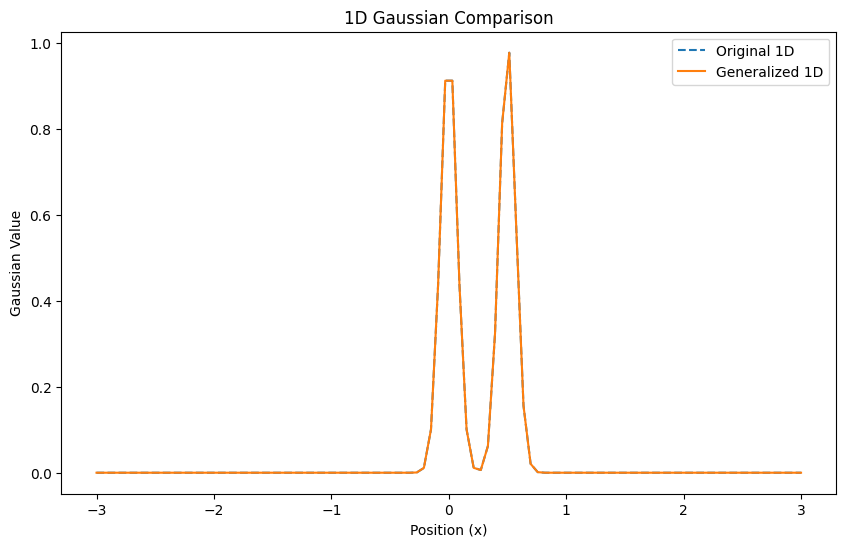

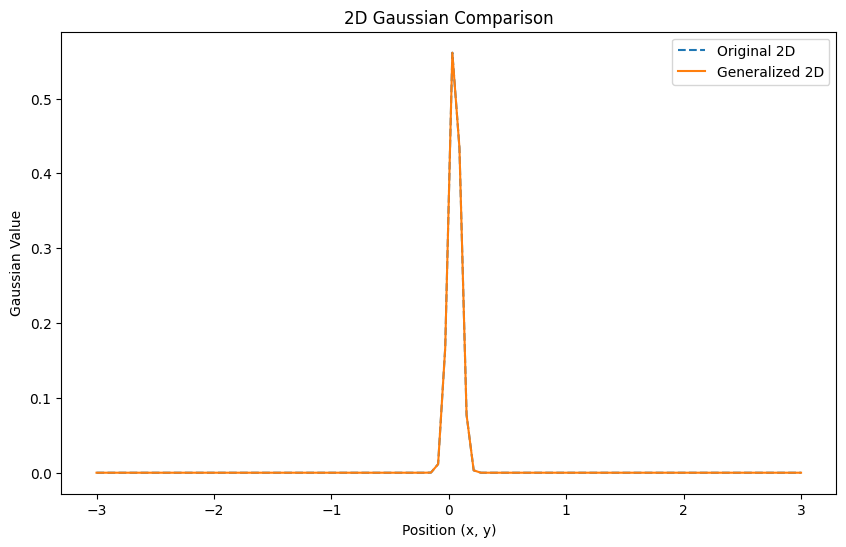

In [31]:
# Generate linspace for 1D and 2D positions
x_vals = np.linspace(-3, 3, 100)  # For 1D Gaussian
positions_1D = np.array([[x, 0, 0] for x in x_vals])  # ASE atoms-like 1D positions


# Generate 2D grid for positions
x_vals_2D = np.linspace(-3, 3, 100)
y_vals_2D = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x_vals_2D, y_vals_2D)
positions_2D = np.array([[x, y, 0] for x, y in zip(x_vals_2D, y_vals_2D)]) 

# Compute values for 1D and 2D Gaussian using linspace
generalized_1D_vals = [gaussian_1D.gaussian_ND(np.array([[x, 0, 0]]), dims=1) for x in x_vals]
original_1D_vals = [original_gaussian_1D(np.array([[x, 0, 0]]), old_means_1D) for x in x_vals]

generalized_2D_vals = [gaussian_2D.gaussian_ND(np.array([[x, y, 0]]), dims=2) for x, y in zip(x_vals_2D, y_vals_2D)]
original_2D_vals = [original_gaussian_2D(np.array([[x, y, 0]]), old_means_2D) for x, y in zip(x_vals_2D, y_vals_2D)]

# Plot the comparison for 1D
plt.figure(figsize=(10, 6))
plt.plot(x_vals, original_1D_vals, label="Original 1D", linestyle='--')
plt.plot(x_vals, generalized_1D_vals, label="Generalized 1D", linestyle='-')
plt.title("1D Gaussian Comparison")
plt.xlabel("Position (x)")
plt.ylabel("Gaussian Value")
plt.legend()
plt.show()


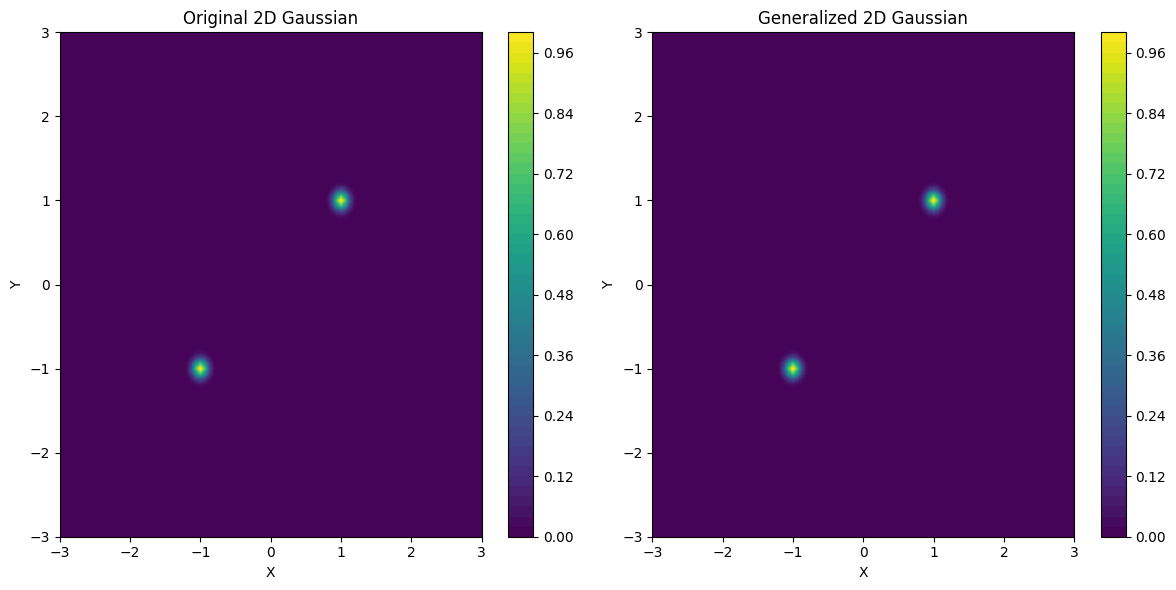

In [34]:
# Generate 2D grid for positions
x_vals_2D = np.linspace(-3, 3, 100)
y_vals_2D = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x_vals_2D, y_vals_2D)

# Convert meshgrid to list of positions
positions_2D = np.array([[x, y, 0] for x, y in zip(X.flatten(), Y.flatten())])  # 2D Gaussian positions

# Means for Gaussian: assume two means for 2D Gaussian (1.0, 1.0) and (-1.0, -1.0)
old_means_2D = np.array([[1.0, 1.0], [-1.0, -1.0]])  # For 2D

# Initialize GaussianND class for 2D case
gaussian_2D = GaussianND(old_means_2D, std_dev=0.1, bias_height=1.0)

# Compute values for 2D Gaussian using grid positions
generalized_2D_vals = np.array([gaussian_2D.gaussian_ND(np.array([[x, y, 0]]), dims=2) for x, y in zip(X.flatten(), Y.flatten())])
original_2D_vals = np.array([original_gaussian_2D(np.array([[x, y, 0]]), old_means_2D) for x, y in zip(X.flatten(), Y.flatten())])

# Reshape results to grid shape for 2D plotting
generalized_2D_vals = generalized_2D_vals.reshape(X.shape)
original_2D_vals = original_2D_vals.reshape(X.shape)

# Plot 2D Gaussian comparison using contourf for generalized and original
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Original 2D Gaussian
contour1 = ax[0].contourf(X, Y, original_2D_vals, levels=50, cmap='viridis')
ax[0].set_title("Original 2D Gaussian")
ax[0].set_xlabel("X")
ax[0].set_ylabel("Y")
fig.colorbar(contour1, ax=ax[0])

# Generalized 2D Gaussian
contour2 = ax[1].contourf(X, Y, generalized_2D_vals, levels=50, cmap='viridis')
ax[1].set_title("Generalized 2D Gaussian")
ax[1].set_xlabel("X")
ax[1].set_ylabel("Y")
fig.colorbar(contour2, ax=ax[1])

plt.tight_layout()
plt.show()